# Choose a clustering granularity in Allen Cortex with GAUGE

**Your task.** Decide whether a finer clustering gains enough molecular support to justify keeping more groups. Generate five Leiden candidates for the same cells, measure their predictability from expression, then compare candidates as the cost per group changes.

The data are a fixed sample of 3,000 mouse cortical cells from the Allen Cortex reference. The asset contains 2,000 highly variable genes and curated class labels. Use the class labels only to interpret the result after selection.

## 0. Install GAUGE and place the data beside this notebook

Use Python 3.10 or newer. In a terminal on macOS or Linux, create and activate an environment.

```bash
python -m venv .venv
source .venv/bin/activate
```

In Windows PowerShell, activate it with `.venv\Scripts\Activate.ps1`.

Install the software and tutorial dependencies from the public GAUGE repository. If you already have a checkout, run the install command from its root.

```bash
git clone https://github.com/zhanglabtools/gauge-sc.git
cd gauge-sc
python -m pip install ".[tutorial]" jupyterlab
```

To install from a downloaded wheel, pass its local path with the tutorial extra. This example uses version `0.1.0a2`.

```bash
python -m pip install "./gauge_sc-0.1.0a2-py3-none-any.whl[tutorial]" jupyterlab
```

Download **`allen_cortex.h5ad`** (about 2.2 MB) from [tutorial-data-v1](https://github.com/zhanglabtools/gauge-sc/releases/tag/tutorial-data-v1) and put it beside this notebook. You can also run this command from the notebook folder.

```bash
curl -fLO https://github.com/zhanglabtools/gauge-sc/releases/download/tutorial-data-v1/allen_cortex.h5ad
```

From that folder, run `jupyter lab`, open this notebook and select the installed Python environment as its kernel. If the file is elsewhere, set `data_dir` to the folder containing it. GAUGE verifies the pinned local file. The first cell should print **3,000 cells × 2,000 features**.

In [1]:
import os
from pathlib import Path

import gauge_sc as gauge

data_dir = Path(os.environ.get("GAUGE_TUTORIAL_DATA") or ".")
adata = gauge.datasets.load_example("allen_cortex", data_dir=data_dir, download=False)
print(f"GAUGE {gauge.__version__} · {adata.n_obs:,} cells × {adata.n_vars:,} features")

GAUGE 0.1.0a2 · 3,000 cells × 2,000 features


## 1. Fix the molecular view and generate candidate groupings

The expression matrix was normalized over all source genes, log1p-transformed and then restricted to highly variable genes. Use it as loaded. Compute 30 principal components to represent expression, build one neighbor graph and vary Leiden resolution to produce five label sets. A larger resolution generally produces more groups. Using the same cells, graph and representation lets us focus on the effect of changing granularity.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display

sc.set_figure_params(dpi=110, frameon=False)
sc.pp.pca(adata, n_comps=30, random_state=0)
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca", random_state=0)
candidate_keys = []
for resolution in [0.3, 0.6, 0.9, 1.2, 1.5]:
    key = f"leiden_{resolution}"
    sc.tl.leiden(
        adata, resolution=resolution, key_added=key, random_state=0,
        flavor="igraph", directed=False, n_iterations=2,
    )
    candidate_keys.append(key)

## 2. Measure molecular support and apply a cost per group

`evaluate()` predicts each candidate's fixed labels from the same PCs. Here ITCA is the mean over five stratified test folds. It summarizes how much information about the grouping is predictable from expression. `select()` uses **ITCA+ = ITCA − δ × K**, where `K` is the number of groups and `δ` is the cost per group in nats. A finer candidate wins when its additional ITCA exceeds the added cost. Once ITCA is computed, `select()` can sweep penalties without refitting the classifiers.

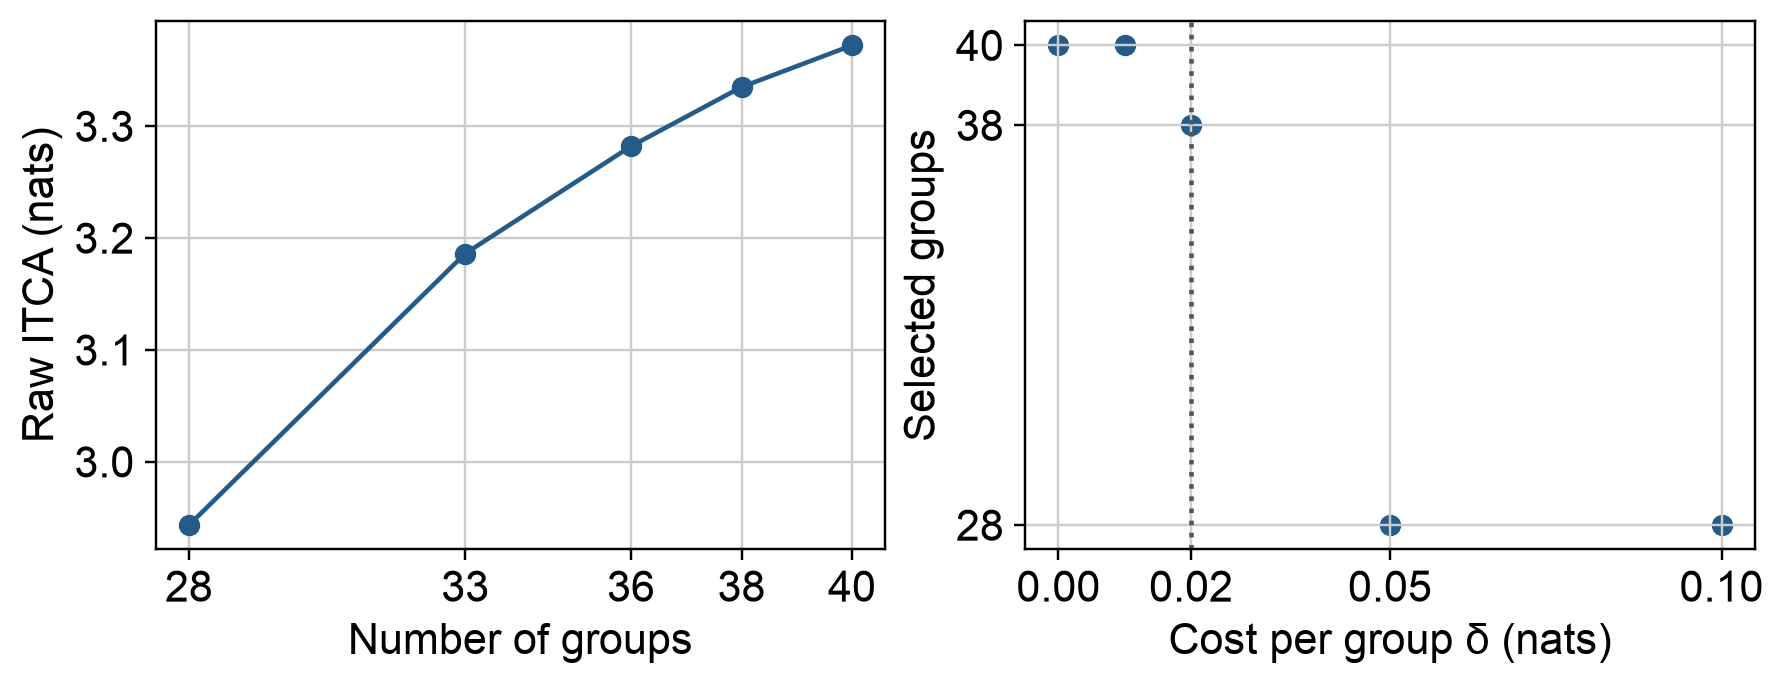

In [3]:
result = gauge.evaluate(
    adata, groupby=candidate_keys, views={"molecular": {"obsm": "X_pca"}},
    n_splits=5, random_state=0, aggregation="fold_mean",
)
penalties = [0, 0.01, 0.02, 0.05, 0.1]
selection = gauge.select(result, view="molecular", delta=penalties)

profile = result.table.sort_values("n_groups")
fig, axes = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
axes[0].plot(profile.n_groups, profile.itca, "o-", color="#245b88")
axes[0].set(
    xlabel="Number of groups", ylabel="Raw ITCA (nats)",
    xticks=profile.n_groups.unique(),
)
axes[1].scatter(selection.path.delta, selection.path.n_groups, color="#245b88")
axes[1].axvline(0.02, linestyle=":", color="#555555")
axes[1].set(
    xlabel="Cost per group δ (nats)", ylabel="Selected groups",
    xticks=[0, 0.02, 0.05, 0.1], yticks=sorted(selection.path.n_groups.unique()),
)
plt.show()

**Read the two plots together.** The left panel shows raw predictive support for every candidate. Each dot in the right panel shows the winning group count at one tested cost. The dotted line marks `δ=0.02`, the example used below. Pick a cost range that fits the biological scale you want to retain and inspect the nearby choices before committing to a partition.

## 3. Read the two scores at δ = 0.02

Compare the two resolutions at δ=0.02 using the scores computed in your run. Compare the gain in raw ITCA with the extra cost for the finer partition, then look at the difference between the two ITCA+ scores. Display rounding happens after selection.

In [4]:
delta = 0.02
scored = selection.table.loc[np.isclose(selection.table.delta, delta)].set_index("groupby")
pair = scored.loc[["leiden_1.2", "leiden_1.5"]]
with pd.option_context("display.precision", 9):
    display(pair[["n_groups", "itca", "penalty", "itca_plus", "selected"]].rename(columns={
        "n_groups": "Groups (K)", "itca": "Raw ITCA (nats)", "penalty": "Cost δ×K",
        "itca_plus": "ITCA+ (nats)", "selected": "Selected",
    }))

lower, higher = pair.iloc[0], pair.iloc[1]
gain = higher.itca - lower.itca
extra_cost = higher.penalty - lower.penalty
net = higher.itca_plus - lower.itca_plus
chosen = scored.loc[scored.selected].iloc[0]
print(f"Raw gain {gain:.9f} − extra cost {extra_cost:.9f} = net gain {net:+.9f} nats.")
print(f"Selected at δ={delta}: {chosen.name} ({chosen.n_groups:.0f} groups).")

,Groups (K),Raw ITCA (nats),Cost δ×K,ITCA+ (nats),Selected
groupby,,,,,
leiden_1.2,38,3.334989396,0.76,2.574989396,True
leiden_1.5,40,3.372321005,0.80,2.572321005,False


Raw gain 0.037331608 − extra cost 0.040000000 = net gain -0.002668392 nats.
Selected at δ=0.02: leiden_1.2 (38 groups).


**Why a different environment can flip the choice.** Two extra groups cost `2 × 0.02 = 0.04` nats. In the reviewer's controlled comparison, the 40-group candidate's ITCA stayed at `3.370304372`. Changing the OpenBLAS kernel from Haswell to SkylakeX increased the 38-group ITCA from `3.328778308` to `3.330909534`. That increase of about `0.00213` nats outweighed the Haswell lead of about `0.00153` nats for the 40-group candidate. SkylakeX then selected 38 groups by about `0.00061` nats. The reviewer held the labels and folds fixed and traced the change to small PCA differences and two changed held-out predictions for the 38-group candidate.

These are paired measurements from one x86/OpenBLAS setup. Other runs can have different PCs or partitions. Record your numerical backend, read the unrounded margin and inspect both label maps when the scores are this close. The saved notebook contains its runtime record. [Numerical reproducibility](../../docs/numerical-reproducibility.md).

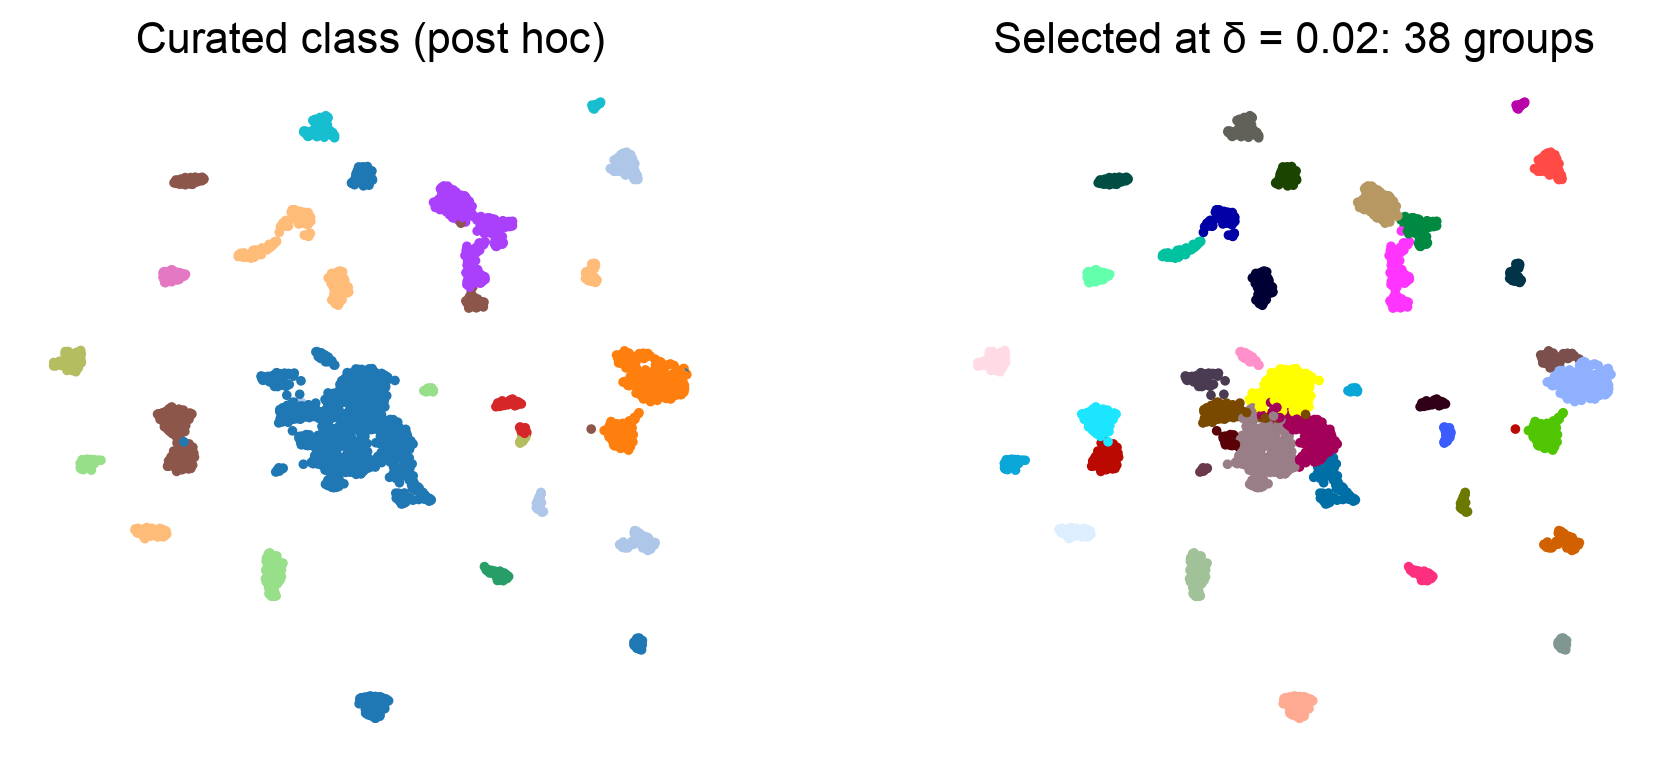

In [5]:
adata.obs["selected_granularity"] = adata.obs[chosen.name].copy()
sc.tl.umap(adata, random_state=0)
sc.pl.umap(
    adata, color=["class", "selected_granularity"], legend_loc="none",
    title=["Curated class (post hoc)", f"Selected at δ = 0.02: {chosen.n_groups:.0f} groups"],
)

**Read the maps.** Both panels use the same UMAP coordinates. The left shows broad curated classes, and the right shows the selected Leiden labels. Colors identify groups within each panel independently. Use these maps to locate where the chosen partition subdivides broad structure. If a close alternative changes an area you care about, inspect its cell counts and marker support before choosing a granularity.

## Apply the selection to your own AnnData

Use one AnnData with the same cells in every candidate, at least two existing candidate label columns in `obs`, and a common molecular representation in `obsm`. The example runs on this tutorial's two close candidates. Change the data object, candidate columns, embedding key and penalty grid for your own comparison. The resulting table shows the winner at each cost.

In [6]:
user_adata = adata  # Replace with sc.read_h5ad("my_sample.h5ad").
groupings = ["leiden_1.2", "leiden_1.5"]  # Your candidate columns in .obs.
embedding = "X_pca"  # Your common molecular view in .obsm.
user_penalties = [0.01, 0.02, 0.05]  # Inspect a range around the decision.

user_result = gauge.evaluate(
    user_adata, groupby=groupings, views={"molecular": {"obsm": embedding}},
    n_splits=5, random_state=0, aggregation="fold_mean",
)
user_selection = gauge.select(user_result, view="molecular", delta=user_penalties)
display(user_selection.path[["delta", "groupby", "n_groups", "itca_plus"]].round(9))

,delta,groupby,n_groups,itca_plus
0,0.01,leiden_1.5,40,2.972321
1,0.02,leiden_1.2,38,2.574989
2,0.05,leiden_1.2,38,1.434989


## Go further

[Paper reproduction](../../docs/paper-reproduction.md) tracks the full Figure 5 analysis on 20,000 cells and 110 Leiden candidates. Its recorded selection was 45 groups. The tutorial has its own 3,000 cells, five candidates and decision margin.

[Use GAUGE with your agent](../../docs/agents.md) to compare your fixed candidates. Provide the common molecular input and the scale you want to retain. Ask for raw and penalized scores at nearby costs and where the best candidates differ on the cell map.